# GBT: train, test, compare
Run training and validation first. After choosing the configuration on validation data, set RUN_TRAINING=False, PREFERRED_RUN to the chosen run name, and RUN_TEST=True. Test results must not be used for tuning.
All model outputs are stored under Model_GBT/outputs/.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
import json
import sys
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark import StorageLevel
from pyspark.ml import PipelineModel
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.functions import vector_to_array

ROOT = next((candidate for base in [Path.cwd(), *Path.cwd().parents]
             for candidate in [base, base / 'Model_GBT', base / 'task2/Model_GBT']
             if (candidate / 'src/train_gbt.py').is_file()), None)
assert ROOT is not None, 'Cannot locate task2/Model_GBT/src/train_gbt.py'
sys.path.insert(0, str(ROOT / 'src'))
from train_gbt import run_training
print('Project root:', ROOT)

Project root: /nfs/home/svu/le.pan/singapore-rainfall-analysis-and-prediction/task2/Model_GBT


## Dataset Configuration

In [12]:
DATASET_ROOT = Path(
    '/scratch/e1496655/task2/final-1458499.stdct-mgmt-02/prepared/'
)

# Original sampling configuration
TRAIN_FRACTION = 0.02
VALIDATION_FRACTION = 0.10

# Original GBT hyperparameters
MAX_ITER = 20
MAX_DEPTH = 4
STEP_SIZE = 0.1
SEED = 5208

# Reserve test data for final evaluation inside the training function
EVALUATE_TEST = False

# Experiment output directory (used only if RUN_TRAINING=True)
OUTPUT_ROOT = (
    ROOT / 'outputs'
    / datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
)

# Notebook workflow controls
RUN_TRAINING = False      # True: train a NEW model; False: reuse a saved model
PREFERRED_RUN = None       # None: newest completed run; or a folder name
RUN_TEST = False           # Evaluate the frozen model on the full test split

GBT_RUNS_ROOT = ROOT / 'outputs'
print('Dataset:', DATASET_ROOT, '| exists:', DATASET_ROOT.exists())
print('Runs directory:', GBT_RUNS_ROOT)
print('Train new model:', RUN_TRAINING, '| Evaluate test:', RUN_TEST)

Dataset: /scratch/e1496655/task2/final-1458499.stdct-mgmt-02/prepared | exists: True
Runs directory: /nfs/home/svu/le.pan/singapore-rainfall-analysis-and-prediction/task2/Model_GBT/outputs
Train new model: False | Evaluate test: False


## Spark Session Initialization

In [7]:
spark = (
    SparkSession.builder
    .appName('Rainfall_GBT_Training')
    .master('local[4]')
    .config('spark.driver.memory', '16g')
    .config('spark.sql.shuffle.partitions', '16')
    .getOrCreate()
)
spark.sparkContext.setLogLevel('WARN')
print('Spark version:', spark.version)
print('Spark master:', spark.sparkContext.master)
print('Driver max heap (GB):', round(
    spark.sparkContext._jvm.java.lang.Runtime.getRuntime().maxMemory() / 1024**3, 2))

Spark version: 3.5.6
Spark master: local[4]
Driver max heap (GB): 16.0


## Saved Experiments — Discovery and Validation Comparison

Compare existing experiments using **validation metrics only**. Only runs with a saved PipelineModel are selectable; incomplete runs are labeled in the table.

In [8]:
def discover_runs(root):
    rows = []
    if not root.is_dir():
        return pd.DataFrame()
    for folder in sorted(root.iterdir()):
        if not folder.is_dir():
            continue
        manifest_path = folder / 'run_manifest.json'
        manifest = json.loads(manifest_path.read_text()) if manifest_path.is_file() else {}
        has_model = (folder / 'model' / 'metadata').is_dir()
        metrics_path = folder / 'metrics.csv'
        row = {'run': folder.name, 'status': manifest.get('status', 'unknown'),
               'has_model': has_model, 'has_validation': metrics_path.is_file(),
               'train_fraction': manifest.get('train_fraction'),
               'validation_fraction': manifest.get('validation_fraction'),
               'max_iter': manifest.get('max_iter'),
               'max_depth': manifest.get('max_depth'),
               'step_size': manifest.get('step_size'), 'seed': manifest.get('seed')}
        rows.append(row)
    return pd.DataFrame(rows)

runs_df = discover_runs(GBT_RUNS_ROOT)
if runs_df.empty:
    print('No saved experiments found yet.')
else:
    display(runs_df.sort_values('run', ascending=False).reset_index(drop=True))

,run,status,has_model,has_validation,train_fraction,validation_fraction,max_iter,max_depth,step_size,seed
0,20261015T094831590078Z,complete,True,True,0.02,0.1,20,4,0.1,5208


In [9]:
validation_frames = []
if not runs_df.empty:
    for run_name in runs_df.loc[runs_df['has_validation'], 'run']:
        path = GBT_RUNS_ROOT / run_name / 'metrics.csv'
        df = pd.read_csv(path)
        if 'split' in df.columns:
            df = df.loc[df['split'] == 'validation'].copy()
        df['run'] = run_name
        validation_frames.append(df)
validation_comparison = (pd.concat(validation_frames, ignore_index=True)
                         if validation_frames else pd.DataFrame())
if validation_comparison.empty:
    print('No saved validation metrics yet.')
else:
    columns = ['run', 'threshold_mm', 'samples', 'positive_rate',
               'areaUnderROC', 'areaUnderPR', 'brier']
    display(validation_comparison[columns].sort_values(['threshold_mm','run']).round(5))

,run,threshold_mm,samples,positive_rate,areaUnderROC,areaUnderPR,brier
0,20261015T094831590078Z,0.0,668341,0.06690,0.87773,0.63800,0.03739
1,20261015T094831590078Z,1.0,668341,0.02643,0.85700,0.49466,0.01908
2,20261015T094831590078Z,5.0,668341,0.00890,0.84325,0.29658,0.00888
3,20261015T094831590078Z,10.0,668341,0.00423,0.84972,0.19112,0.00555


## GBT Model — Train or Load

**Default:** load a saved model. Training happens only when `RUN_TRAINING = True`. When choosing a model, use the validation comparison above rather than test metrics.

In [10]:
if RUN_TRAINING:
    SAVED_RUN = OUTPUT_ROOT
    model, metrics = run_training(
        spark=spark,
        dataset_root=DATASET_ROOT,
        output_root=OUTPUT_ROOT,
        train_fraction=TRAIN_FRACTION,
        validation_fraction=VALIDATION_FRACTION,
        max_iter=MAX_ITER,
        max_depth=MAX_DEPTH,
        step_size=STEP_SIZE,
        seed=SEED,
        evaluate_test=EVALUATE_TEST
    )
    print('New model trained and saved:', SAVED_RUN / 'model')
else:
    if runs_df.empty:
        raise FileNotFoundError('No saved model found. Set RUN_TRAINING=True to train a new one.')
    candidates = runs_df.loc[runs_df['has_model'] & runs_df['has_validation'] & (runs_df['status'] == 'complete')].copy()
    if candidates.empty:
        raise FileNotFoundError('No saved model with validation metrics found.')
    if PREFERRED_RUN is not None:
        if PREFERRED_RUN not in set(candidates['run']):
            raise ValueError(f'PREFERRED_RUN not found or incomplete: {PREFERRED_RUN}')
        SAVED_RUN = GBT_RUNS_ROOT / PREFERRED_RUN
    else:
        SAVED_RUN = GBT_RUNS_ROOT / sorted(candidates['run'])[-1]
    model = PipelineModel.load(str(SAVED_RUN / 'model'))
    print('Loaded saved model; no training performed.')

metrics_df = pd.read_csv(SAVED_RUN / 'metrics.csv')
if 'split' in metrics_df.columns:
    metrics_df = metrics_df.loc[metrics_df['split'] == 'validation'].copy()
metrics_df = metrics_df.sort_values('threshold_mm').reset_index(drop=True)
print('Selected experiment:', SAVED_RUN.name)
display(metrics_df[['threshold_mm','samples','positives','positive_rate',
                    'areaUnderROC','areaUnderPR','brier']].round(5))

[Stage 3:=================================================>         (5 + 1) / 6]

Training counts: [{'threshold_mm': 1.0, 'samples': 680053, 'positives': 15931.0}, {'threshold_mm': 10.0, 'samples': 680053, 'positives': 2655.0}, {'threshold_mm': 5.0, 'samples': 680053, 'positives': 5509.0}, {'threshold_mm': 0.0, 'samples': 680053, 'positives': 40950.0}]


26/10/15 17:54:53 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.blas.JNIBLAS
                                                                                

{'samples': 668341, 'positives': 44713.0, 'brier': 0.03739437731760529, 'split': 'validation', 'threshold_mm': 0.0, 'positive_rate': 0.06690147694066352, 'areaUnderROC': 0.8777281910406882, 'areaUnderPR': 0.6379972728205175}
{'samples': 668341, 'positives': 17662.0, 'brier': 0.019082346130878294, 'split': 'validation', 'threshold_mm': 1.0, 'positive_rate': 0.02642662951996062, 'areaUnderROC': 0.8570015253017623, 'areaUnderPR': 0.49466147056813925}
{'samples': 668341, 'positives': 5946.0, 'brier': 0.008876017723848982, 'split': 'validation', 'threshold_mm': 5.0, 'positive_rate': 0.008896656048334608, 'areaUnderROC': 0.8432509997262555, 'areaUnderPR': 0.2965785110563906}
{'samples': 668341, 'positives': 2828.0, 'brier': 0.005550870221287012, 'split': 'validation', 'threshold_mm': 10.0, 'positive_rate': 0.00423137290694421, 'areaUnderROC': 0.849717928831288, 'areaUnderPR': 0.19112021426597262}
New model trained and saved: /nfs/home/svu/le.pan/singapore-rainfall-analysis-and-prediction/tas

,threshold_mm,samples,positives,positive_rate,areaUnderROC,areaUnderPR,brier
0,0.0,668341,44713.0,0.06690,0.87773,0.63800,0.03739
1,1.0,668341,17662.0,0.02643,0.85700,0.49466,0.01908
2,5.0,668341,5946.0,0.00890,0.84325,0.29658,0.00888
3,10.0,668341,2828.0,0.00423,0.84972,0.19112,0.00555


## Validation Performance Visualization

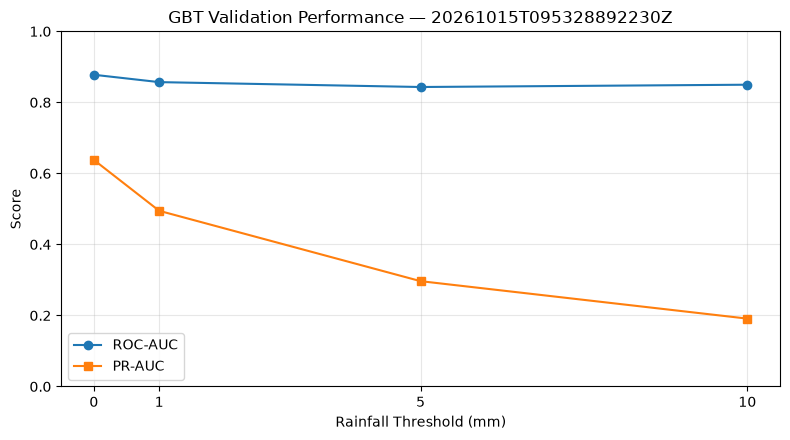

In [13]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(metrics_df['threshold_mm'], metrics_df['areaUnderROC'], marker='o', label='ROC-AUC')
ax.plot(metrics_df['threshold_mm'], metrics_df['areaUnderPR'], marker='s', label='PR-AUC')
ax.set(xlabel='Rainfall Threshold (mm)', ylabel='Score',
       title=f'GBT Validation Performance — {SAVED_RUN.name}')
ax.set_xticks([0, 1, 5, 10]); ax.set_ylim(0, 1)
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## Feature Importance

GBT split-based importance is a model interpretation aid, **not** a causal effect.

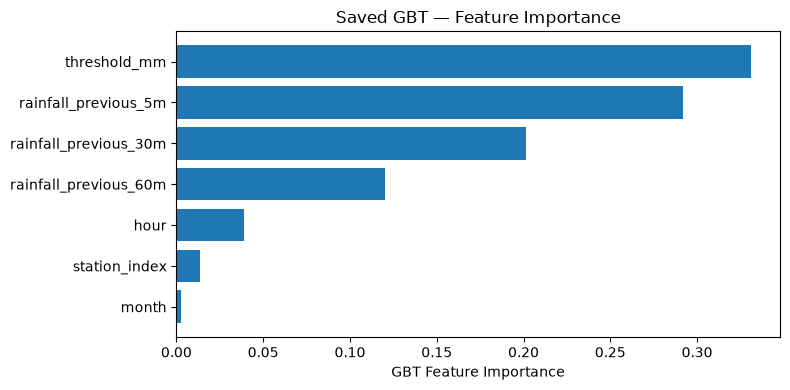

,feature,importance
0,threshold_mm,0.331205
1,rainfall_previous_5m,0.291732
2,rainfall_previous_30m,0.201315
3,rainfall_previous_60m,0.120338
4,hour,0.039063
5,station_index,0.013534
6,month,0.002812


In [14]:
import train_gbt
importance = model.stages[-1].featureImportances.toArray()
features = train_gbt.FEATURES
feature_importance_df = (pd.DataFrame({'feature': features, 'importance': importance})
                         .sort_values('importance', ascending=True))
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(feature_importance_df['feature'], feature_importance_df['importance'])
ax.set(xlabel='GBT Feature Importance', title='Saved GBT — Feature Importance')
plt.tight_layout(); plt.show()
display(feature_importance_df.sort_values('importance', ascending=False).reset_index(drop=True))

## Test Set Evaluation — Selected Saved Model

Uses the **full** test split, without retraining. Each explicit test evaluation saves a new directory, including actual/predicted comparisons. Run once for final reporting; do not use test scores to choose hyperparameters.

In [15]:
from test_gbt import run_testing

test_metrics_df = pd.DataFrame()
test_reliability_df = pd.DataFrame()
if RUN_TEST:
    TEST_OUTPUT = run_testing(spark, DATASET_ROOT, SAVED_RUN)
    test_metrics_df = pd.read_csv(TEST_OUTPUT / 'test_metrics.csv')
    test_reliability_df = pd.read_csv(TEST_OUTPUT / 'test_reliability_bins.csv')
    display(test_metrics_df.round(5))
    display(pd.read_csv(TEST_OUTPUT / 'prediction_preview.csv'))
    display(pd.read_csv(TEST_OUTPUT / 'confusion_matrix.csv'))
    comparison = metrics_df.merge(test_metrics_df, on='threshold_mm', suffixes=('_validation', '_test'))
    display(comparison[['threshold_mm', 'areaUnderPR_validation', 'areaUnderPR_test',
                        'brier_validation', 'brier_test', 'baseline_brier', 'brier_skill']])
    comparison.to_csv(TEST_OUTPUT / 'validation_test_comparison.csv', index=False)
else:
    print('Select a frozen model before enabling RUN_TEST.')


Select a frozen model before enabling RUN_TEST.


## Test Performance Visualization

In [16]:
if not test_metrics_df.empty:
    fig, ax = plt.subplots(figsize=(8, 4.5))
    xs = range(len(test_metrics_df))
    ax.plot(xs, test_metrics_df['areaUnderROC'], marker='o', label='Test ROC-AUC')
    ax.plot(xs, test_metrics_df['areaUnderPR'], marker='s', label='Test PR-AUC')
    ax.set_xticks(list(xs), [f"> {t:g} mm" for t in test_metrics_df['threshold_mm']])
    ax.set(xlabel='Rainfall threshold (next 30 minutes)', ylabel='Area under curve',
           title=f'GBT Test Performance — {SAVED_RUN.name}')
    ax.set_ylim(0, 1); ax.legend(); ax.grid(alpha=0.25)
    plt.tight_layout(); plt.show()
else:
    print('No test results to plot.')

No test results to plot.


## Test Probability Reliability

Each point shows the mean predicted probability versus observed event frequency. Small bins can be noisy; the accompanying table includes their sample counts.

In [17]:
if not test_reliability_df.empty:
    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    ax.plot([0,1],[0,1],'--',color='gray',label='Perfect calibration')
    for threshold, part in test_reliability_df.groupby('threshold_mm'):
        ax.plot(part['mean_probability'],part['observed_rate'],marker='o',
                label=f"> {threshold:g} mm")
    ax.set(xlim=(0,1),ylim=(0,1),xlabel='Mean predicted probability',
           ylabel='Observed event rate',title='GBT Test — Reliability Diagram')
    ax.legend(); ax.grid(alpha=0.25)
    plt.tight_layout(); plt.show()
    display(test_reliability_df.sort_values(['threshold_mm','bin']).reset_index(drop=True).round(5))
else:
    print('No reliability bins available.')

No reliability bins available.


## Spark Shutdown

Run this cell only when finished. If you need Spark again, rerun the Spark initialization cell.

In [18]:
spark.stop()
print("Spark session stopped.")

Spark session stopped.
